In [1]:
import lsdb

from hats.catalog import ExtensionProperties
from lsdb_rubin import DP2FieldSearch
from upath import UPath

lsdb.show_versions()


--------      SYSTEM INFO      --------
python        : 3.13.18
python-bits   : 64
OS            : Linux
OS-release    : 5.14.0-570.60.1+27.2.el9_6_ciq.x86_64
Version       : #1 SMP PREEMPT_DYNAMIC Sat Oct 31 18:59:02 UTC 2026
machine       : x86_64
processor     : x86_64
byteorder     : little
LC_ALL        : 
LANG          : C.UTF-8
--------   INSTALLED VERSIONS   --------
lsdb          : 0.11.2
hats          : 0.11.2
nested-pandas : 0.7.3
pandas        : 3.0.6
numpy         : 2.3.5
dask          : 2026.6.0
pyarrow       : 26.0.1
fsspec        : 2026.6.0


# DG2. Federated Data Access

Metric: LSDB query can retrieve the core data from one location and join auxiliary data at a separate location.

Rationale: Demonstrate that the infrastructure can enable model training without all data centralized at a single location.

In [2]:
collection_path = UPath("/sdf/data/rubin/cosmicdata/lsdb/genesis/milestone2")
milestone2 = lsdb.open_catalog(collection_path)
milestone2

,object_id_mmu_legacysurvey_dr10_south_21,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,object_id_mmu_desi_edr_sv3,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec,image_psf_fwhm_g,image_scale_g,image_psf_fwhm_r,image_scale_r
npartitions=548,,,,,,,,,,,
"Order: 7, Pixel: 41472",string[pyarrow],double[pyarrow],double[pyarrow],string[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow]
...,...,...,...,...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112605",...,...,...,...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112607",...,...,...,...,...,...,...,...,...,...,...


View the loaded and available extensions:

In [3]:
print(f"Loaded extensions: {milestone2.extensions}")
print(f"Available extensions: {milestone2.all_extensions}")

Loaded extensions: ()
Available extensions: {'cutouts': 'milestone2_cutouts.properties', 'spectra': 'milestone2_spectra.properties'}


The extensions are defined locally, in their respective properties files. The data is located remotely.

In [4]:
ExtensionProperties.read_from_file(collection_path / "milestone2_cutouts.properties")

name                       milestone2_cutouts
catalog_type               extension
primary_catalog            milestone2
primary_column             object_id_mmu_legacysurvey_dr10_south_21
join_catalog               hf://datasets/LSDB/milestone2_cutouts
join_column                object_id_mmu_legacysurvey_dr10_south_21
extension_columns          image_flux_g image_mask_g image_ivar_g image_flux_r image_mask_r image_ivar_r
extension_join_style       left
shares_primary_coordinates True
extension_product_type     image

In [5]:
ExtensionProperties.read_from_file(collection_path / "milestone2_spectra.properties")

name                       milestone2_spectra
catalog_type               extension
primary_catalog            milestone2
primary_column             object_id_mmu_legacysurvey_dr10_south_21
join_catalog               https://data.lsdb.io/unstable/milestone2_spectra
join_column                object_id_mmu_legacysurvey_dr10_south_21
extension_columns          spectrum
extension_join_style       left
shares_primary_coordinates True
extension_product_type     spectra

Search for a region of interest:

In [6]:
milestone2 = milestone2.search(DP2FieldSearch("DESI SV3 R1"))

Load the cutouts from HuggingFace:

Building task graph...


Computing Catalog:   0%|          | 0/10 [00:00<?, ?it/s]

,object_id_mmu_legacysurvey_dr10_south_21,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,object_id_mmu_desi_edr_sv3,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec,image_psf_fwhm_g,image_scale_g,image_psf_fwhm_r,image_scale_r,image_flux_g,image_mask_g,image_ivar_g,image_flux_r,image_mask_r,image_ivar_r
1801201788245847905,1798m017-6451,179.855478,-1.691771,39627745465993311,179.855478,-1.691771,0.001520,1.665503,0.262000,1.492458,0.262000,0.0331-0.00237,21,6.72e+054.81e+05,0.101-0.00304,21,3.75e+052.64e+05
1801201796851523055,1798m017-7476,179.871207,-1.687170,39627745465993672,179.871202,-1.687163,0.028542,1.704805,0.262000,1.520931,0.262000,0.00927-0.00245,21,7.09e+055.75e+05,0.0295-0.00339,21,4.6e+053.32e+05
1801201937201069454,1798m017-3093,179.798073,-1.707065,39627745465992192,179.798073,-1.707065,0.000000,1.554352,0.262000,1.366422,0.262000,0.115-0.00151,21,9.44e+054.22e+05,0.175-0.00178,21,5.99e+053.15e+05
1801202060484213422,1798m017-1462,179.771428,-1.694685,39627745465991620,179.771431,-1.694687,0.013869,1.691869,0.262000,1.496693,0.262000,0.00544-0.00245,21,9.51e+055.64e+05,0.0109-0.00326,21,5.52e+053.02e+05
1801202100787405415,1798m017-5312,179.836980,-1.701088,39627745465992851,179.836980,-1.701086,0.005069,1.530178,0.262000,1.368396,0.262000,0.0617-0.0024,10,9.1e+054.84e+05,0.143-0.00311,10,5.76e+052.68e+05

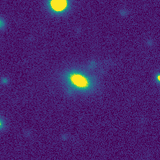
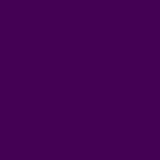
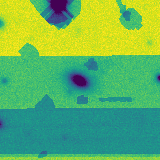
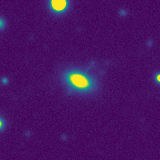
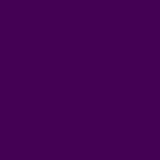
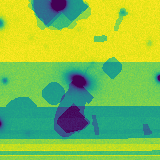
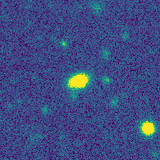
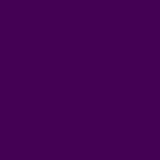
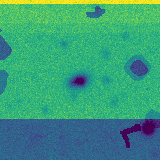
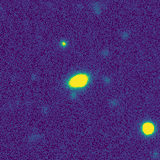
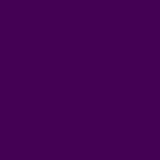
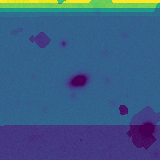
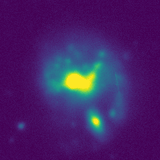
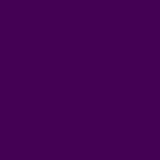
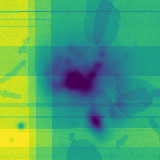
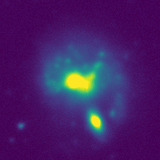
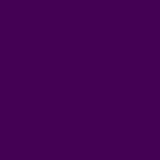
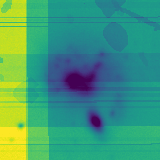
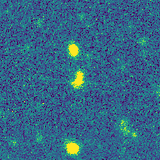
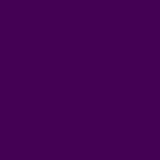
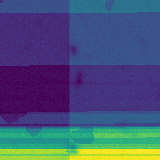
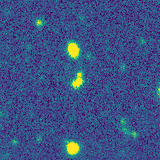
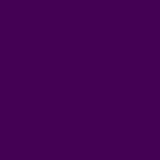
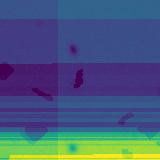
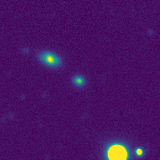
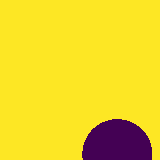
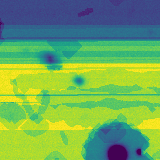
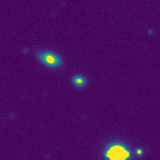
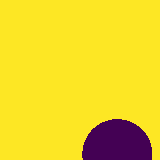
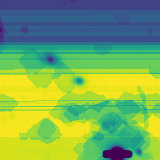

In [7]:
milestone2 = milestone2.load_extension("cutouts")
milestone2.head()

Load the spectra, from UW, on top of the existing Catalog:

Building task graph...


Computing Catalog:   0%|          | 0/18 [00:00<?, ?it/s]

object_id_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                                    
1801201788245847905                            1798m017-6451   
1801201796851523055                            1798m017-7476   
1801201937201069454                            1798m017-3093   
1801202060484213422                            1798m017-1462   
1801202100787405415                            1798m017-5312   

                     ra_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                              
1801201788245847905                         179.855478   
1801201796851523055                         179.871207   
1801201937201069454                         179.798073   
1801202060484213422                         179.771428   
1801202100787405415                          179.83698   

                     dec_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                               
1801201788245847905                           -1.691771   
1801201796851523055                            -1.68717   
1801201937201069454                           -1.707065   
1801202060484213422                           -1.694685   
1801202100787405415                           -1.701088   

                    object_id_mmu_desi_edr_sv3  ra_mmu_desi_edr_sv3  \
_healpix_29                                                           
1801201788245847905          39627745465993311           179.855478   
1801201796851523055          39627745465993672           179.871202   
1801201937201069454          39627745465992192           179.798073   
1801202060484213422          39627745465991620           179.771431   
1801202100787405415          39627745465992851            179.83698   

                     dec_mmu_desi_edr_sv3  _dist_arcsec  image_psf_fwhm_g  \
_healpix_29                                                                 
1801201788245847905             -1.691771       0.00152          1.665503   
1801201796851523055             -1.687163      0.028542          1.704805   
1801201937201069454             -1.707065           0.0          1.554352   
1801202060484213422             -1.694687      0.013869          1.691869   
1801202100787405415             -1.701086      0.005069          1.530178   

                     image_scale_g  image_psf_fwhm_r  image_scale_r  \
_healpix_29                                                           
1801201788245847905          0.262          1.492458          0.262   
1801201796851523055          0.262          1.520931          0.262   
1801201937201069454          0.262          1.366422          0.262   
1801202060484213422          0.262          1.496693          0.262   
1801202100787405415          0.262          1.368396          0.262   

                          image_flux_g    image_mask_g       image_ivar_g  \
_healpix_29                                                                 
1801201788245847905  [160×160] float32  [160×160] bool  [160×160] float32   
1801201796851523055  [160×160] float32  [160×160] bool  [160×160] float32   
1801201937201069454  [160×160] float32  [160×160] bool  [160×160] float32   
1801202060484213422  [160×160] float32  [160×160] bool  [160×160] float32   
1801202100787405415  [160×160] float32  [160×160] bool  [160×160] float32   

                          image_flux_r    image_mask_r       image_ivar_r  \
_healpix_29                                                                 
1801201788245847905  [160×160] float32  [160×160] bool  [160×160] float32   
1801201796851523055  [160×160] float32  [160×160] bool  [160×160] float32   
1801201937201069454  [160×160] float32  [160×160] bool  [160×160] float32   
1801202060484213422  [160×160] float32  [160×160] bool  [160×160] float32   
1801202100787405415  [160×160] float32  [160×160] bool  [160×160] float32   

                                                              spectrum  
_healpix_29                                                  
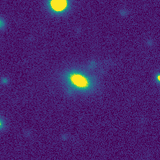
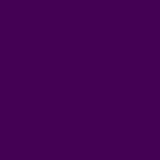
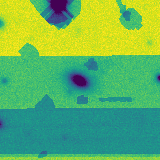
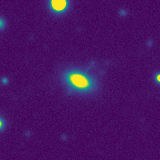
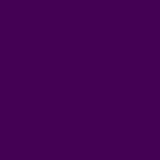
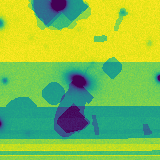
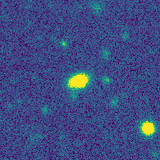
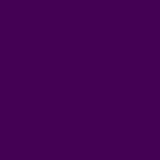
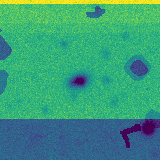
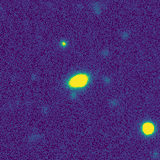
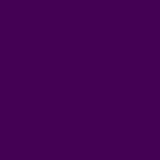
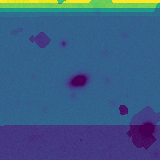
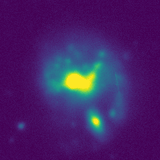
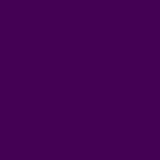
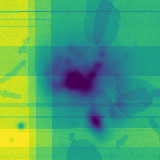
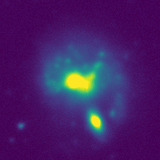
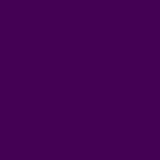
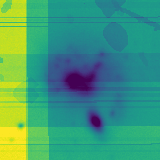
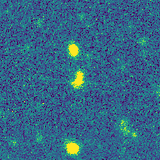
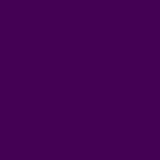
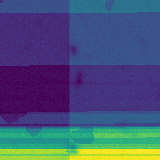
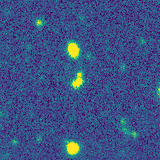
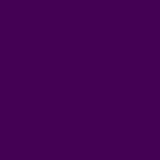
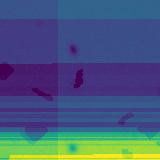
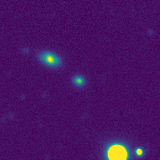
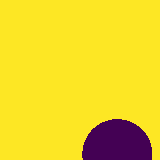
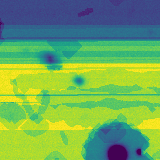
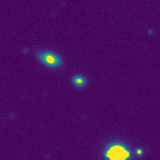
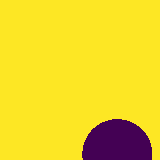
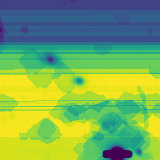

In [8]:
milestone2 = milestone2.load_extension("spectra")
milestone2.head()

In [9]:
print(f"Loaded extensions: {milestone2.extensions}")

Loaded extensions: ('cutouts', 'spectra')
